<a href="https://colab.research.google.com/github/zubaeteee20210205109-droid/Thesis/blob/main/A_Deep_Learning_Based_Hybrid_CNN%E2%80%93Transformer_Approach_for_Multi_Class_Skin_Lesion_Classification_Using_HAM10000.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ============================================================
# BLOCK 1 : MOUNT GOOGLE DRIVE
# ============================================================

from google.colab import drive

drive.mount("/content/drive")

print("=" * 60)
print("Google Drive mounted successfully ✅")
print("=" * 60)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive mounted successfully ✅


In [2]:
# ============================================================
# BLOCK 2 : CHECK GPU
# ============================================================

import tensorflow as tf

print("=" * 60)
print("TensorFlow Version :", tf.__version__)
print("=" * 60)

print("Built with CUDA :", tf.test.is_built_with_cuda())

gpus = tf.config.list_physical_devices("GPU")

print("Available GPUs :", gpus)

if gpus:

    print("\n✅ GPU DETECTED")

    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)

    print(
        "GPU Name :",
        tf.config.experimental.get_device_details(
            gpus[0]
        ).get("device_name")
    )

else:

    print("\n❌ NO GPU DETECTED")
    print("TensorFlow is running on CPU.")

print("=" * 60)

TensorFlow Version : 2.20.0
Built with CUDA : True
Available GPUs : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

✅ GPU DETECTED
GPU Name : Tesla T4


In [5]:
# ============================================================
# BLOCK 3 : COPY HAM10000 DATASET TO LOCAL SSD
# ============================================================

import os
import shutil

SOURCE = "/content/drive/MyDrive/Skin Cancer MNIST HAM10000"
DESTINATION = "/content/HAM10000"

# Remove old local copy
if os.path.exists(DESTINATION):
    print("Removing old local HAM10000 dataset...")
    shutil.rmtree(DESTINATION)

# Create destination
os.makedirs(DESTINATION, exist_ok=True)

print("Copying HAM10000 dataset to local SSD...")

# Copy files and folders recursively
for root, dirs, files in os.walk(SOURCE):

    relative_path = os.path.relpath(root, SOURCE)
    destination_root = os.path.join(
        DESTINATION,
        relative_path
    )

    os.makedirs(destination_root, exist_ok=True)

    for file in files:

        source_file = os.path.join(root, file)
        destination_file = os.path.join(
            destination_root,
            file
        )

        shutil.copy2(
            source_file,
            destination_file
        )

print("Dataset copied successfully ✅")
print("Local Path :", DESTINATION)

print("\nFiles/Folders:")

for item in os.listdir(DESTINATION):
    print(item)

Removing old local HAM10000 dataset...
Copying HAM10000 dataset to local SSD...
Dataset copied successfully ✅
Local Path : /content/HAM10000

Files/Folders:
HAM10000_images_part_2
hmnist_28_28_RGB.csv
split
HAM10000_images_part_1
hmnist_8_8_L.csv
hmnist_8_8_RGB.csv
hmnist_28_28_L.csv
HAM10000_metadata.csv


In [6]:
# ============================================================
# BLOCK 4 : IMPORTS
# ============================================================

import os
import shutil
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit

from sklearn.utils.class_weight import compute_class_weight

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    auc,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    cohen_kappa_score
)

import tensorflow as tf

from tensorflow.keras import (
    layers,
    models,
    callbacks
)

from tensorflow.keras.preprocessing.image import ImageDataGenerator

from tensorflow.keras.applications.efficientnet_v2 import (
    preprocess_input
)

In [7]:
# ============================================================
# BLOCK 5 : DATASET PATHS
# ============================================================

DATASET_PATH = "/content/HAM10000"

METADATA_PATH = os.path.join(DATASET_PATH, "HAM10000_metadata.csv")

IMG_FOLDERS = [
    os.path.join(DATASET_PATH, "HAM10000_images_part_1"),
    os.path.join(DATASET_PATH, "HAM10000_images_part_2")
]

print("Metadata:")
print(METADATA_PATH)

print("\nImage Folders:")
for folder in IMG_FOLDERS:
    print(folder)

print("\nDataset Exists:", os.path.exists(DATASET_PATH))
print("Metadata Exists:", os.path.exists(METADATA_PATH))

for folder in IMG_FOLDERS:
    print(os.path.basename(folder),
          "Exists:", os.path.exists(folder))

Metadata:
/content/HAM10000/HAM10000_metadata.csv

Image Folders:
/content/HAM10000/HAM10000_images_part_1
/content/HAM10000/HAM10000_images_part_2

Dataset Exists: True
Metadata Exists: True
HAM10000_images_part_1 Exists: True
HAM10000_images_part_2 Exists: True


In [8]:
# ============================================================
# BLOCK 6 : LOAD METADATA
# ============================================================

metadata = pd.read_csv(
    METADATA_PATH
)

print("=" * 60)
print("Metadata Shape:", metadata.shape)
print("=" * 60)

print("\nColumns:")
print(metadata.columns.tolist())

print("\nFirst 5 Rows:")
print(metadata.head())

print("\nDiagnostic Class Counts:")
print(
    metadata["dx"].value_counts()
)

print("\nUnique Lesions:")
print(
    metadata["lesion_id"].nunique()
)

print("\nUnique Images:")
print(
    metadata["image_id"].nunique()
)

Metadata Shape: (10015, 7)

Columns:
['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization']

First 5 Rows:
     lesion_id      image_id   dx dx_type   age   sex localization
0  HAM_0000118  ISIC_0027419  bkl   histo  80.0  male        scalp
1  HAM_0000118  ISIC_0025030  bkl   histo  80.0  male        scalp
2  HAM_0002730  ISIC_0026769  bkl   histo  80.0  male        scalp
3  HAM_0002730  ISIC_0025661  bkl   histo  80.0  male        scalp
4  HAM_0001466  ISIC_0031633  bkl   histo  75.0  male          ear

Diagnostic Class Counts:
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64

Unique Lesions:
7470

Unique Images:
10015


In [9]:
# ============================================================
# BLOCK 7 : LOAD ALL IMAGE PATHS FROM BOTH FOLDERS
# ============================================================

image_path_dict = {}
valid_extensions = (".jpg", ".jpeg", ".JPG", ".JPEG", ".png", ".PNG")
total_found = 0

for folder in IMG_FOLDERS:
    print("\nScanning folder:", folder)

    if not os.path.exists(folder):
        print("❌ Folder not found:", folder)
        continue

    folder_count = 0

    for root, dirs, files in os.walk(folder):
        for file in files:
            if file.lower().endswith(valid_extensions):
                full_path = os.path.join(root, file)
                image_path_dict[file] = full_path
                folder_count += 1
                total_found += 1

    print(
        f"Images found in {os.path.basename(folder)} : {folder_count}"
    )

print("\n" + "=" * 60)
print("TOTAL IMAGES FOUND :", total_found)
print("UNIQUE IMAGE NAMES :", len(image_path_dict))
print("=" * 60)

print("\nExample image filenames:")
for i, filename in enumerate(image_path_dict.keys()):
    print(filename)
    if i >= 9:
        break


Scanning folder: /content/HAM10000/HAM10000_images_part_1
Images found in HAM10000_images_part_1 : 5000

Scanning folder: /content/HAM10000/HAM10000_images_part_2
Images found in HAM10000_images_part_2 : 5015

TOTAL IMAGES FOUND : 10015
UNIQUE IMAGE NAMES : 10015

Example image filenames:
ISIC_0025799.jpg
ISIC_0024791.jpg
ISIC_0027375.jpg
ISIC_0024529.jpg
ISIC_0024447.jpg
ISIC_0028391.jpg
ISIC_0027971.jpg
ISIC_0027896.jpg
ISIC_0028065.jpg
ISIC_0025581.jpg


In [10]:
# ============================================================
# BLOCK 8 : MATCH METADATA WITH IMAGE FILES
# ============================================================

file_paths = []
labels = []
groups = []
missing_images = []

for _, row in metadata.iterrows():

    image_id = str(row["image_id"]).strip()
    img_name = image_id + ".jpg"
    label = str(row["dx"]).strip()
    lesion_id = str(row["lesion_id"]).strip()

    if img_name in image_path_dict:

        file_paths.append(image_path_dict[img_name])
        labels.append(label)
        groups.append(lesion_id)

    else:

        found = False

        for extension in [".jpeg", ".JPG", ".JPEG", ".png", ".PNG"]:

            alternative_name = image_id + extension

            if alternative_name in image_path_dict:

                file_paths.append(image_path_dict[alternative_name])
                labels.append(label)
                groups.append(lesion_id)
                found = True
                break

        if not found:
            missing_images.append(img_name)

# ------------------------------------------------------------
# CONVERT TO NUMPY ARRAYS
# ------------------------------------------------------------

file_paths = np.array(file_paths)
labels = np.array(labels)
groups = np.array(groups)

print("=" * 60)
print("METADATA & IMAGE MATCHING RESULT")
print("=" * 60)
print("Total Metadata Rows :", len(metadata))
print("Matched Images      :", len(file_paths))
print("Missing Images      :", len(missing_images))
print("Total Lesions       :", len(np.unique(groups)))
print("Total Classes       :", len(np.unique(labels)))
print("=" * 60)

# ------------------------------------------------------------
# SAFETY CHECK
# ------------------------------------------------------------

if len(file_paths) == 0:

    print("\n❌ ERROR: ZERO images matched!")
    print("\nFirst metadata image IDs:")
    print(metadata["image_id"].head(10).tolist())

    print("\nFirst detected filenames:")
    print(list(image_path_dict.keys())[:10])

else:

    print("\n✅ Images successfully matched with metadata!")

# ------------------------------------------------------------
# SHOW MISSING IMAGES
# ------------------------------------------------------------

if len(missing_images) > 0:

    print("\nFirst 10 missing image names:")
    print(missing_images[:10])

METADATA & IMAGE MATCHING RESULT
Total Metadata Rows : 10015
Matched Images      : 10015
Missing Images      : 0
Total Lesions       : 7470
Total Classes       : 7

✅ Images successfully matched with metadata!


In [11]:
# ============================================================
# BLOCK 9 : CHECK DATASET AND DEFINE CLASSES
# ============================================================

# ------------------------------------------------------------
# SAFETY CHECK
# ------------------------------------------------------------

if len(file_paths) == 0:

    raise ValueError(
        "❌ file_paths is EMPTY! "
        "Block 7 and Block 8 did not match "
        "the images correctly."
    )

if len(labels) == 0:

    raise ValueError(
        "❌ labels is EMPTY!"
    )

if len(groups) == 0:

    raise ValueError(
        "❌ groups is EMPTY!"
    )

# ------------------------------------------------------------
# DEFINE HAM10000 CLASSES
# ------------------------------------------------------------

classes = sorted(
    np.unique(labels)
)

NUM_CLASSES = len(classes)

print("=" * 60)
print("DATASET SUMMARY")
print("=" * 60)

print(
    "Total Images :",
    len(file_paths)
)

print(
    "Total Labels :",
    len(labels)
)

print(
    "Total Groups :",
    len(groups)
)

print(
    "Unique Lesions :",
    len(np.unique(groups))
)

print(
    "Classes :",
    classes
)

print(
    "NUM_CLASSES :",
    NUM_CLASSES
)

print("=" * 60)

# ------------------------------------------------------------
# EXPECTED HAM10000 CLASSES
# ------------------------------------------------------------

expected_classes = [
    "akiec",
    "bcc",
    "bkl",
    "df",
    "mel",
    "nv",
    "vasc"
]

print("\nExpected HAM10000 Classes:")
print(expected_classes)

# ------------------------------------------------------------
# VERIFY 7 CLASSES
# ------------------------------------------------------------

if NUM_CLASSES != 7:

    raise ValueError(
        f"❌ Expected 7 classes, "
        f"but found {NUM_CLASSES}: "
        f"{classes}"
    )

print(
    "\n✅ HAM10000 contains exactly 7 classes."
)

# ------------------------------------------------------------
# CLASS DISTRIBUTION
# ------------------------------------------------------------

print("\nCLASS DISTRIBUTION")
print("=" * 60)

unique_labels, counts = np.unique(
    labels,
    return_counts=True
)

for label, count in zip(
    unique_labels,
    counts
):

    print(
        f"{label} : {count}"
    )

print("=" * 60)

DATASET SUMMARY
Total Images : 10015
Total Labels : 10015
Total Groups : 10015
Unique Lesions : 7470
Classes : [np.str_('akiec'), np.str_('bcc'), np.str_('bkl'), np.str_('df'), np.str_('mel'), np.str_('nv'), np.str_('vasc')]
NUM_CLASSES : 7

Expected HAM10000 Classes:
['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']

✅ HAM10000 contains exactly 7 classes.

CLASS DISTRIBUTION
akiec : 327
bcc : 514
bkl : 1099
df : 115
mel : 1113
nv : 6705
vasc : 142


In [12]:
# ============================================================
# BLOCK 10 : GROUP-WISE 70 / 15 / 15 SPLIT
# ============================================================

# ------------------------------------------------------------
# SAFETY CHECK
# ------------------------------------------------------------

assert len(file_paths) > 0

assert len(file_paths) == len(labels), \
    "file_paths and labels length mismatch!"

assert len(file_paths) == len(groups), \
    "file_paths and groups length mismatch!"

print("=" * 60)
print("STARTING GROUP-WISE SPLIT")
print("=" * 60)

print(
    "Total Images Before Split :",
    len(file_paths)
)

print(
    "Total Unique Lesions :",
    len(np.unique(groups))
)

print("=" * 60)

# ------------------------------------------------------------
# FIRST SPLIT
# 70% TRAIN
# 30% TEMPORARY
# ------------------------------------------------------------

gss1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_idx, temp_idx = next(
    gss1.split(
        file_paths,
        labels,
        groups=groups
    )
)

# ------------------------------------------------------------
# TRAIN DATA
# ------------------------------------------------------------

train_paths = file_paths[
    train_idx
]

train_labels = labels[
    train_idx
]

train_groups = groups[
    train_idx
]

# ------------------------------------------------------------
# TEMP DATA
# ------------------------------------------------------------

temp_paths = file_paths[
    temp_idx
]

temp_labels = labels[
    temp_idx
]

temp_groups = groups[
    temp_idx
]

# ------------------------------------------------------------
# SECOND SPLIT
# 50% OF TEMP = VALIDATION
# 50% OF TEMP = TEST
# ------------------------------------------------------------

gss2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_idx, test_idx = next(
    gss2.split(
        temp_paths,
        temp_labels,
        groups=temp_groups
    )
)

# ------------------------------------------------------------
# VALIDATION DATA
# ------------------------------------------------------------

val_paths = temp_paths[
    val_idx
]

val_labels = temp_labels[
    val_idx
]

val_groups = temp_groups[
    val_idx
]

# ------------------------------------------------------------
# TEST DATA
# ------------------------------------------------------------

test_paths = temp_paths[
    test_idx
]

test_labels = temp_labels[
    test_idx
]

test_groups = temp_groups[
    test_idx
]

# ------------------------------------------------------------
# FINAL SPLIT SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 60)

print(
    "FINAL 70 / 15 / 15 SPLIT"
)

print("=" * 60)

print(
    "Train Images :",
    len(train_paths)
)

print(
    "Validation Images :",
    len(val_paths)
)

print(
    "Test Images :",
    len(test_paths)
)

print("=" * 60)

# ------------------------------------------------------------
# ACTUAL PERCENTAGES
# ------------------------------------------------------------

total_images = len(file_paths)

print("\nACTUAL SPLIT PERCENTAGE")

print(
    f"Train : "
    f"{len(train_paths) / total_images * 100:.2f}%"
)

print(
    f"Validation : "
    f"{len(val_paths) / total_images * 100:.2f}%"
)

print(
    f"Test : "
    f"{len(test_paths) / total_images * 100:.2f}%"
)

print("=" * 60)

# ------------------------------------------------------------
# LESION COUNTS
# ------------------------------------------------------------

print("\nLESION DISTRIBUTION")

print(
    "Train Lesions :",
    len(np.unique(train_groups))
)

print(
    "Validation Lesions :",
    len(np.unique(val_groups))
)

print(
    "Test Lesions :",
    len(np.unique(test_groups))
)

print("=" * 60)

# ------------------------------------------------------------
# CLASS DISTRIBUTION
# ------------------------------------------------------------

print("\nTRAIN CLASS DISTRIBUTION")

for cls in classes:

    print(
        f"{cls} :",
        np.sum(train_labels == cls)
    )

print("\nVALIDATION CLASS DISTRIBUTION")

for cls in classes:

    print(
        f"{cls} :",
        np.sum(val_labels == cls)
    )

print("\nTEST CLASS DISTRIBUTION")

for cls in classes:

    print(
        f"{cls} :",
        np.sum(test_labels == cls)
    )

print("=" * 60)

print(
    "\n✅ GROUP-WISE 70 / 15 / 15 SPLIT "
    "COMPLETED SUCCESSFULLY!"
)

STARTING GROUP-WISE SPLIT
Total Images Before Split : 10015
Total Unique Lesions : 7470

FINAL 70 / 15 / 15 SPLIT
Train Images : 7002
Validation Images : 1519
Test Images : 1494

ACTUAL SPLIT PERCENTAGE
Train : 69.92%
Validation : 15.17%
Test : 14.92%

LESION DISTRIBUTION
Train Lesions : 5229
Validation Lesions : 1120
Test Lesions : 1121

TRAIN CLASS DISTRIBUTION
akiec : 207
bcc : 381
bkl : 741
df : 89
mel : 770
nv : 4718
vasc : 96

VALIDATION CLASS DISTRIBUTION
akiec : 57
bcc : 65
bkl : 206
df : 19
mel : 156
nv : 991
vasc : 25

TEST CLASS DISTRIBUTION
akiec : 63
bcc : 68
bkl : 152
df : 7
mel : 187
nv : 996
vasc : 21

✅ GROUP-WISE 70 / 15 / 15 SPLIT COMPLETED SUCCESSFULLY!


In [13]:
# ============================================================
# BLOCK 11 : GROUP LEAKAGE CHECK
# ============================================================

print("=" * 60)
print("GROUP LEAKAGE CHECK")
print("=" * 60)

train_group_set = set(
    train_groups
)

val_group_set = set(
    val_groups
)

test_group_set = set(
    test_groups
)

# ------------------------------------------------------------
# OVERLAPS
# ------------------------------------------------------------

train_val_overlap = (
    train_group_set.intersection(
        val_group_set
    )
)

train_test_overlap = (
    train_group_set.intersection(
        test_group_set
    )
)

val_test_overlap = (
    val_group_set.intersection(
        test_group_set
    )
)

print(
    "\nTrain ∩ Validation :",
    len(train_val_overlap)
)

print(
    "Train ∩ Test :",
    len(train_test_overlap)
)

print(
    "Validation ∩ Test :",
    len(val_test_overlap)
)

# ------------------------------------------------------------
# FINAL RESULT
# ------------------------------------------------------------

if (
    len(train_val_overlap) == 0
    and
    len(train_test_overlap) == 0
    and
    len(val_test_overlap) == 0
):

    print(
        "\n✅ SUCCESS: "
        "No lesion-level leakage detected!"
    )

else:

    print(
        "\n❌ WARNING: "
        "Lesion-level leakage detected!"
    )

GROUP LEAKAGE CHECK

Train ∩ Validation : 0
Train ∩ Test : 0
Validation ∩ Test : 0

✅ SUCCESS: No lesion-level leakage detected!


In [14]:
# ============================================================
# BLOCK 12 : RESET SPLIT DATASET FOLDER
# ============================================================

BASE_DIR = "/content/HAM10000_Split_Dataset"

# ------------------------------------------------------------
# REMOVE OLD SPLIT DATASET
# ------------------------------------------------------------

if os.path.exists(BASE_DIR):

    print(
        "Removing old split dataset..."
    )

    shutil.rmtree(
        BASE_DIR
    )

# ------------------------------------------------------------
# CREATE TRAIN / VALIDATION / TEST
# ------------------------------------------------------------

for split in [
    "Train",
    "Validation",
    "Test"
]:

    for cls in classes:

        os.makedirs(
            os.path.join(
                BASE_DIR,
                split,
                cls
            ),
            exist_ok=True
        )

print(
    "Clean split folder created successfully ✅"
)

Clean split folder created successfully ✅


In [15]:
# ============================================================
# BLOCK 13 : COPY FILES INTO TRAIN / VALIDATION / TEST
# ============================================================

def copy_files(
    paths,
    labels,
    split_name
):

    for path, label in zip(
        paths,
        labels
    ):

        filename = os.path.basename(
            path
        )

        destination = os.path.join(
            BASE_DIR,
            split_name,
            label,
            filename
        )

        if not os.path.exists(
            destination
        ):

            shutil.copy2(
                path,
                destination
            )


# ------------------------------------------------------------
# COPY TRAIN
# ------------------------------------------------------------

copy_files(
    train_paths,
    train_labels,
    "Train"
)

# ------------------------------------------------------------
# COPY VALIDATION
# ------------------------------------------------------------

copy_files(
    val_paths,
    val_labels,
    "Validation"
)

# ------------------------------------------------------------
# COPY TEST
# ------------------------------------------------------------

copy_files(
    test_paths,
    test_labels,
    "Test"
)

print(
    "All files copied successfully ✅"
)

All files copied successfully ✅


In [16]:
# ============================================================
# BLOCK 14 : FINAL LEAKAGE CHECK AFTER COPYING
# ============================================================

# ------------------------------------------------------------
# FILE DUPLICATE CHECK
# ------------------------------------------------------------

train_files = set(
    os.path.basename(path)
    for path in train_paths
)

val_files = set(
    os.path.basename(path)
    for path in val_paths
)

test_files = set(
    os.path.basename(path)
    for path in test_paths
)

print("=" * 60)
print("FILE DUPLICATE CHECK")
print("=" * 60)

print(
    "Train ∩ Validation :",
    len(
        train_files.intersection(
            val_files
        )
    )
)

print(
    "Train ∩ Test :",
    len(
        train_files.intersection(
            test_files
        )
    )
)

print(
    "Validation ∩ Test :",
    len(
        val_files.intersection(
            test_files
        )
    )
)

# ------------------------------------------------------------
# LESION GROUP CHECK
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("LESION GROUP OVERLAP")
print("=" * 60)

print(
    "Train ∩ Validation :",
    len(
        set(train_groups).intersection(
            set(val_groups)
        )
    )
)

print(
    "Train ∩ Test :",
    len(
        set(train_groups).intersection(
            set(test_groups)
        )
    )
)

print(
    "Validation ∩ Test :",
    len(
        set(val_groups).intersection(
            set(test_groups)
        )
    )
)

# ------------------------------------------------------------
# FINAL RESULT
# ------------------------------------------------------------

if (

    len(
        train_files.intersection(
            val_files
        )
    ) == 0

    and

    len(
        train_files.intersection(
            test_files
        )
    ) == 0

    and

    len(
        val_files.intersection(
            test_files
        )
    ) == 0

    and

    len(
        set(train_groups).intersection(
            set(val_groups)
        )
    ) == 0

    and

    len(
        set(train_groups).intersection(
            set(test_groups)
        )
    ) == 0

    and

    len(
        set(val_groups).intersection(
            set(test_groups)
        )
    ) == 0

):

    print(
        "\n✅ SUCCESS: "
        "Dataset is completely leakage-free!"
    )

else:

    print(
        "\n❌ WARNING: Leakage detected!"
    )

FILE DUPLICATE CHECK
Train ∩ Validation : 0
Train ∩ Test : 0
Validation ∩ Test : 0

LESION GROUP OVERLAP
Train ∩ Validation : 0
Train ∩ Test : 0
Validation ∩ Test : 0

✅ SUCCESS: Dataset is completely leakage-free!


In [17]:
# ============================================================
# BLOCK 15 : DATA GENERATORS
# ============================================================

IMG_SIZE = (
    224,
    224
)

BATCH_SIZE = 32

# ------------------------------------------------------------
# TRAIN DATA AUGMENTATION
# ------------------------------------------------------------

train_datagen = ImageDataGenerator(

    preprocessing_function=preprocess_input,

    rotation_range=20,

    width_shift_range=0.10,

    height_shift_range=0.10,

    zoom_range=0.20,

    horizontal_flip=True,

    fill_mode="nearest"
)

# ------------------------------------------------------------
# VALIDATION DATA
# ------------------------------------------------------------

val_datagen = ImageDataGenerator(

    preprocessing_function=preprocess_input
)

# ------------------------------------------------------------
# TEST DATA
# ------------------------------------------------------------

test_datagen = ImageDataGenerator(

    preprocessing_function=preprocess_input
)

# ------------------------------------------------------------
# TRAIN GENERATOR
# ------------------------------------------------------------

train_generator = train_datagen.flow_from_directory(

    os.path.join(
        BASE_DIR,
        "Train"
    ),

    target_size=IMG_SIZE,

    batch_size=BATCH_SIZE,

    class_mode="categorical",

    shuffle=True,

    seed=42
)

# ------------------------------------------------------------
# VALIDATION GENERATOR
# ------------------------------------------------------------

val_generator = val_datagen.flow_from_directory(

    os.path.join(
        BASE_DIR,
        "Validation"
    ),

    target_size=IMG_SIZE,

    batch_size=BATCH_SIZE,

    class_mode="categorical",

    shuffle=False
)

# ------------------------------------------------------------
# TEST GENERATOR
# ------------------------------------------------------------

test_generator = test_datagen.flow_from_directory(

    os.path.join(
        BASE_DIR,
        "Test"
    ),

    target_size=IMG_SIZE,

    batch_size=BATCH_SIZE,

    class_mode="categorical",

    shuffle=False
)

# ------------------------------------------------------------
# INFORMATION
# ------------------------------------------------------------

print("\n" + "=" * 60)

print(
    "DATA GENERATORS READY"
)

print("=" * 60)

print(
    "Train Samples :",
    train_generator.samples
)

print(
    "Validation Samples :",
    val_generator.samples
)

print(
    "Test Samples :",
    test_generator.samples
)

print(
    "\nClass Indices:"
)

print(
    train_generator.class_indices
)

print("=" * 60)

Found 7002 images belonging to 7 classes.
Found 1519 images belonging to 7 classes.
Found 1494 images belonging to 7 classes.

DATA GENERATORS READY
Train Samples : 7002
Validation Samples : 1519
Test Samples : 1494

Class Indices:
{'akiec': 0, 'bcc': 1, 'bkl': 2, 'df': 3, 'mel': 4, 'nv': 5, 'vasc': 6}


In [18]:
# ============================================================
# BLOCK 16 : CLASS WEIGHTS
# ============================================================

labels_list = train_generator.classes

# ------------------------------------------------------------
# COMPUTE BALANCED CLASS WEIGHTS
# ------------------------------------------------------------

class_weights_values = compute_class_weight(

    class_weight="balanced",

    classes=np.unique(
        labels_list
    ),

    y=labels_list
)

# ------------------------------------------------------------
# CONVERT TO DICTIONARY
# ------------------------------------------------------------

class_weights = {

    int(class_id): float(weight)

    for class_id, weight in zip(
        np.unique(labels_list),
        class_weights_values
    )
}

# ------------------------------------------------------------
# PRINT CLASS INFORMATION
# ------------------------------------------------------------

print("\n" + "=" * 60)

print(
    "CLASS WEIGHTS"
)

print("=" * 60)

index_to_class = {
    value: key
    for key, value
    in train_generator.class_indices.items()
}

for class_id, weight in class_weights.items():

    print(
        f"{class_id} "
        f"({index_to_class[class_id]}) "
        f": {weight:.4f}"
    )

print("=" * 60)


CLASS WEIGHTS
0 (akiec) : 4.8323
1 (bcc) : 2.6254
2 (bkl) : 1.3499
3 (df) : 11.2392
4 (mel) : 1.2991
5 (nv) : 0.2120
6 (vasc) : 10.4196


In [19]:
# ============================================================
# BLOCK 17 : TRANSFORMER BLOCK
# ============================================================

def transformer_block(x):

    # --------------------------------------------------------
    # FEATURE DIMENSION
    # --------------------------------------------------------

    feature_dim = x.shape[-1]

    # --------------------------------------------------------
    # MULTI-HEAD SELF ATTENTION
    # --------------------------------------------------------

    attn = layers.MultiHeadAttention(

        num_heads=4,

        key_dim=feature_dim // 4
    )(
        x,
        x
    )

    # --------------------------------------------------------
    # RESIDUAL CONNECTION
    # --------------------------------------------------------

    x1 = layers.Add()([
        x,
        attn
    ])

    # --------------------------------------------------------
    # NORMALIZATION
    # --------------------------------------------------------

    x1 = layers.LayerNormalization()(
        x1
    )

    # --------------------------------------------------------
    # FEED FORWARD NETWORK
    # --------------------------------------------------------

    ffn = layers.Dense(
        feature_dim * 2,
        activation="gelu"
    )(x1)

    ffn = layers.Dense(
        feature_dim
    )(ffn)

    # --------------------------------------------------------
    # SECOND RESIDUAL CONNECTION
    # --------------------------------------------------------

    x2 = layers.Add()([
        x1,
        ffn
    ])

    # --------------------------------------------------------
    # SECOND NORMALIZATION
    # --------------------------------------------------------

    x2 = layers.LayerNormalization()(
        x2
    )

    return x2

In [20]:
# ============================================================
# BLOCK 18 : BUILD MODEL
# ============================================================

def build_model(
    num_classes
):

    # --------------------------------------------------------
    # INPUT
    # --------------------------------------------------------

    inputs = layers.Input(
        shape=(224, 224, 3)
    )

    # --------------------------------------------------------
    # EFFICIENTNETV2B0
    # --------------------------------------------------------

    base = (
        tf.keras.applications
        .EfficientNetV2B0(
            include_top=False,
            weights="imagenet",
            input_tensor=inputs
        )
    )

    # --------------------------------------------------------
    # FINE-TUNING
    # LAST 20 LAYERS TRAINABLE
    # --------------------------------------------------------

    base.trainable = True

    for layer in base.layers[:-20]:

        layer.trainable = False

    # --------------------------------------------------------
    # CNN FEATURE MAP
    # --------------------------------------------------------

    x = base.output

    # --------------------------------------------------------
    # FEATURE MAP SHAPE
    # --------------------------------------------------------

    shape = tf.keras.backend.int_shape(
        x
    )

    h = shape[1]

    w = shape[2]

    c = shape[3]

    # --------------------------------------------------------
    # NUMBER OF PATCHES / TOKENS
    # --------------------------------------------------------

    num_patches = h * w

    # --------------------------------------------------------
    # RESHAPE FEATURE MAP
    # --------------------------------------------------------

    x = layers.Reshape(
        (
            num_patches,
            c
        )
    )(x)

    # --------------------------------------------------------
    # POSITIONAL EMBEDDING
    # --------------------------------------------------------

    positions = tf.range(
        start=0,
        limit=num_patches,
        delta=1
    )

    positional_embedding = layers.Embedding(

        input_dim=num_patches,

        output_dim=c

    )(positions)

    x = x + positional_embedding

    # --------------------------------------------------------
    # TRANSFORMER BLOCK 1
    # --------------------------------------------------------

    x = transformer_block(
        x
    )

    # --------------------------------------------------------
    # TRANSFORMER BLOCK 2
    # --------------------------------------------------------

    x = transformer_block(
        x
    )

    # --------------------------------------------------------
    # GLOBAL AVERAGE POOLING
    # --------------------------------------------------------

    x = layers.GlobalAveragePooling1D()(
        x
    )

    # --------------------------------------------------------
    # CLASSIFICATION HEAD
    # --------------------------------------------------------

    x = layers.Dense(
        512,
        activation="relu"
    )(x)

    x = layers.Dropout(
        0.40
    )(x)

    x = layers.Dense(
        256,
        activation="relu"
    )(x)

    x = layers.Dropout(
        0.30
    )(x)

    # --------------------------------------------------------
    # 7-CLASS OUTPUT
    # --------------------------------------------------------

    outputs = layers.Dense(

        num_classes,

        activation="softmax"

    )(x)

    # --------------------------------------------------------
    # CREATE MODEL
    # --------------------------------------------------------

    model = models.Model(
        inputs,
        outputs
    )

    return model


# ------------------------------------------------------------
# BUILD MODEL
# ------------------------------------------------------------

model = build_model(
    NUM_CLASSES
)

model.summary()

24274472/24274472 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 224, 224,  │          0 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        864 │ normalization[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │      4,608 │ stem_activation[… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_bn  │ (None, 112, 112,  │         64 │ block1a_project_… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_ac… │ (None, 112, 112,  │          0 │ block1a_project_… │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_expand_conv │ (None, 56, 56,    │      9,216 │ block1a_project_… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_expand_bn   │ (None, 56, 56,    │        256 │ block2a_expand_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_expand_act… │ (None, 56, 56,    │          0 │ block2a_expand_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_project_co… │ (None, 56, 56,    │      2,048 │ block2a_expand_a… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_project_bn  │ (None, 56, 56,    │        128 │ block2a_project_… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2b_expand_conv │ (None, 56, 56,    │     36,864 │ block2a_project_… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2b_expand_bn   │ (None, 56, 56,    │        512 │ block2b_expand_c… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2b_expand_act… │ (None, 56, 56,    │          0 │ block2b_expand_b

 Total params: 32,950,871 (125.70 MB)

 Trainable params: 27,849,399 (106.24 MB)

 Non-trainable params: 5,101,472 (19.46 MB)

In [21]:
# ============================================================
# BLOCK 19 : COMPILE MODEL
# ============================================================

model.compile(

    optimizer=tf.keras.optimizers.AdamW(

        learning_rate=1e-4,

        weight_decay=1e-4
    ),

    loss="categorical_crossentropy",

    metrics=[
        "accuracy"
    ]
)

print(
    "Model compiled successfully "
    "with Learning Rate = 1e-4 ✅"
)

print(
    "Number of output classes :",
    NUM_CLASSES
)

Model compiled successfully with Learning Rate = 1e-4 ✅
Number of output classes : 7


In [22]:
# ============================================================
# BLOCK 20 : CALLBACKS
# ============================================================
SAVE_DIR = (
    "/content/drive/MyDrive/"
    "HAM10000_Model"
)
os.makedirs(
    SAVE_DIR,
    exist_ok=True
)
# ------------------------------------------------------------
# FILE PATHS
# ------------------------------------------------------------

BEST_MODEL_PATH = os.path.join(
    SAVE_DIR,
    "Best_Model.keras"
)

FINAL_MODEL_PATH = os.path.join(
    SAVE_DIR,
    "Final_Model.keras"
)

CSV_LOG = os.path.join(
    SAVE_DIR,
    "training_log.csv"
)

CLASS_INDEX_PATH = os.path.join(
    SAVE_DIR,
    "class_indices.json"
)

# ------------------------------------------------------------
# SAVE CLASS INDICES
# ------------------------------------------------------------
with open(
    CLASS_INDEX_PATH,
    "w"
) as f:
    json.dump(
        train_generator.class_indices,
        f,
        indent=4
    )
print(
    "Class indices saved successfully ✅"
)
# ------------------------------------------------------------
# CALLBACKS
# ------------------------------------------------------------
callbacks_list = [
    # --------------------------------------------------------
    # SAVE BEST MODEL
    # --------------------------------------------------------
    callbacks.ModelCheckpoint(
        filepath=BEST_MODEL_PATH,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    # --------------------------------------------------------
    # EARLY STOPPING
    # --------------------------------------------------------
    callbacks.EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=8,
    restore_best_weights=True,
    verbose=1
),
    # --------------------------------------------------------
    # REDUCE LEARNING RATE
    # --------------------------------------------------------
    callbacks.ReduceLROnPlateau(

        monitor="val_loss",
        mode="min",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    ),
    # --------------------------------------------------------
    # SAVE TRAINING LOG
    # --------------------------------------------------------
    callbacks.CSVLogger(
        CSV_LOG,
        append=False
    )
]

print(
    "Callbacks ready successfully ✅"
)

print(
    "Best Model Monitor : val_accuracy"
)

print(
    "Early Stopping : val_accuracy"
)

print(
    "Reduce LR Monitor : val_loss"
)

Class indices saved successfully ✅
Callbacks ready successfully ✅
Best Model Monitor : val_accuracy
Early Stopping : val_accuracy
Reduce LR Monitor : val_loss


In [23]:
# ============================================================
# BLOCK 21 : TRAIN MODEL
# ============================================================

print("=" * 70)

print(
    "STARTING MODEL TRAINING"
)

print("=" * 70)

history = model.fit(

    train_generator,

    validation_data=val_generator,

    epochs=25,

    class_weight=class_weights,

    callbacks=callbacks_list,

    verbose=1
)

print("\n" + "=" * 70)

print(
    "MODEL TRAINING COMPLETED ✅"
)

print("=" * 70)

# ------------------------------------------------------------
# BEST VALIDATION ACCURACY
# ------------------------------------------------------------

best_val_accuracy = max(
    history.history[
        "val_accuracy"
    ]
)

best_epoch = (
    np.argmax(
        history.history[
            "val_accuracy"
        ]
    )
    + 1
)

print(
    f"\nBest Validation Accuracy : "
    f"{best_val_accuracy * 100:.2f}%"
)

print(
    f"Best Epoch : {best_epoch}"
)

STARTING MODEL TRAINING
Epoch 1/25
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 798ms/step - accuracy: 0.2885 - loss: 1.9152
Epoch 1: val_accuracy improved from None to 0.55168, saving model to /content/drive/MyDrive/HAM10000_Model/Best_Model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/HAM10000_Model/Best_Model.keras
219/219 ━━━━━━━━━━━━━━━━━━━━ 263s 967ms/step - accuracy: 0.3807 - loss: 1.7368 - val_accuracy: 0.5517 - val_loss: 1.1529 - learning_rate: 1.0000e-04
Epoch 2/25
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 724ms/step - accuracy: 0.4845 - loss: 1.3890
Epoch 2: val_accuracy did not improve from 0.55168
219/219 ━━━━━━━━━━━━━━━━━━━━ 179s 818ms/step - accuracy: 0.5087 - loss: 1.3161 - val_accuracy: 0.4332 - val_loss: 1.4531 - learning_rate: 1.0000e-04
Epoch 3/25
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 666ms/step - accuracy: 0.5494 - loss: 1.1765
Epoch 3: val_accuracy improved from 0.55168 to 0.55892, saving model to /content/drive/MyDrive/HAM10000_Model/Best_Model.keras

Epoch 3: finished sav

In [24]:
# ============================================================
# BLOCK 22 : SAVE FINAL MODEL
# ============================================================

model.save(FINAL_MODEL_PATH)

print("Final model saved successfully ✅")
print("Path:", FINAL_MODEL_PATH)

Final model saved successfully ✅
Path: /content/drive/MyDrive/HAM10000_Model/Final_Model.keras


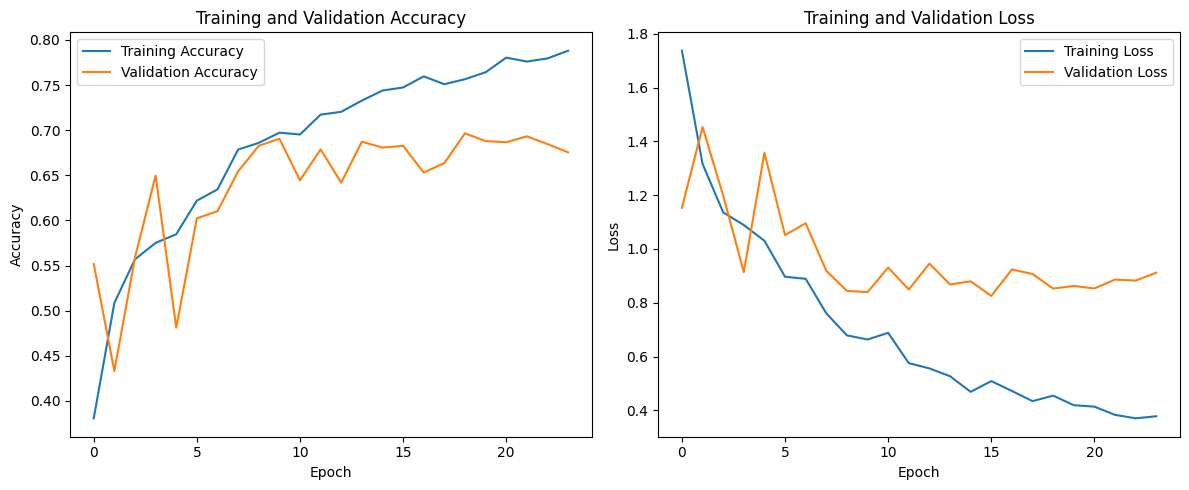

In [25]:
# ============================================================
# BLOCK 23 : TRAINING CURVES
# ============================================================

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [26]:
# ============================================================
# BLOCK 24 : LOAD BEST MODEL
# ============================================================

best_model = tf.keras.models.load_model(BEST_MODEL_PATH)

print("Best model loaded successfully ✅")

Best model loaded successfully ✅


In [27]:
# ============================================================
# BLOCK 25 : TEST SET EVALUATION
# ============================================================

test_loss, test_accuracy = best_model.evaluate(
    test_generator,
    verbose=1
)

print("\nTest Loss     :", test_loss)
print("Test Accuracy :", f"{test_accuracy * 100:.2f}%")

47/47 ━━━━━━━━━━━━━━━━━━━━ 38s 578ms/step - accuracy: 0.7055 - loss: 0.8229

Test Loss     : 0.822865903377533
Test Accuracy : 70.55%


In [28]:
# ============================================================
# BLOCK 26 : GENERATE TEST PREDICTIONS
# ============================================================

test_generator.reset()

y_prob = best_model.predict(
    test_generator,
    verbose=1
)

y_pred = np.argmax(y_prob, axis=1)
y_true = test_generator.classes

print("Predictions generated successfully ✅")
print("Test Samples:", len(y_true))

47/47 ━━━━━━━━━━━━━━━━━━━━ 25s 394ms/step
Predictions generated successfully ✅
Test Samples: 1494


In [29]:
# ============================================================
# BLOCK 27 : CLASSIFICATION REPORT
# ============================================================

print(
    classification_report(
        y_true,
        y_pred,
        target_names=classes,
        digits=4
    )
)

              precision    recall  f1-score   support

       akiec     0.7027    0.4127    0.5200        63
         bcc     0.6167    0.5441    0.5781        68
         bkl     0.3736    0.8553    0.5200       152
          df     0.1765    0.4286    0.2500         7
         mel     0.4028    0.4652    0.4318       187
          nv     0.9520    0.7560    0.8428       996
        vasc     0.7200    0.8571    0.7826        21

    accuracy                         0.7055      1494
   macro avg     0.5634    0.6170    0.5607      1494
weighted avg     0.7917    0.7055    0.7292      1494



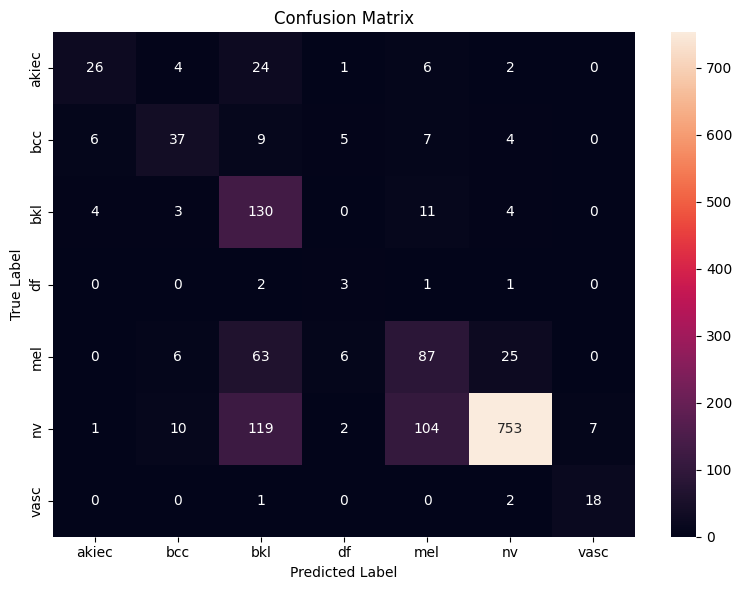

In [30]:
# ============================================================
# BLOCK 28 : CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

In [31]:
# ============================================================
# BLOCK 29 : OVERALL PERFORMANCE METRICS
# ============================================================

precision = precision_score(
    y_true, y_pred, average="weighted"
)

recall = recall_score(
    y_true, y_pred, average="weighted"
)

f1 = f1_score(
    y_true, y_pred, average="weighted"
)

balanced_acc = balanced_accuracy_score(
    y_true, y_pred
)

mcc = matthews_corrcoef(
    y_true, y_pred
)

kappa = cohen_kappa_score(
    y_true, y_pred
)

print("Precision          :", f"{precision:.4f}")
print("Recall             :", f"{recall:.4f}")
print("F1-Score           :", f"{f1:.4f}")
print("Balanced Accuracy  :", f"{balanced_acc:.4f}")
print("MCC                :", f"{mcc:.4f}")
print("Cohen's Kappa      :", f"{kappa:.4f}")

Precision          : 0.7917
Recall             : 0.7055
F1-Score           : 0.7292
Balanced Accuracy  : 0.6170
MCC                : 0.5296
Cohen's Kappa      : 0.5108


In [32]:
# ============================================================
# BLOCK 30 : MULTICLASS ROC-AUC
# ============================================================

y_true_onehot = tf.keras.utils.to_categorical(
    y_true,
    num_classes=NUM_CLASSES
)

roc_auc = roc_auc_score(
    y_true_onehot,
    y_prob,
    multi_class="ovr",
    average="weighted"
)

print(
    "Weighted Multiclass ROC-AUC :",
    f"{roc_auc:.4f}"
)

Weighted Multiclass ROC-AUC : 0.9187


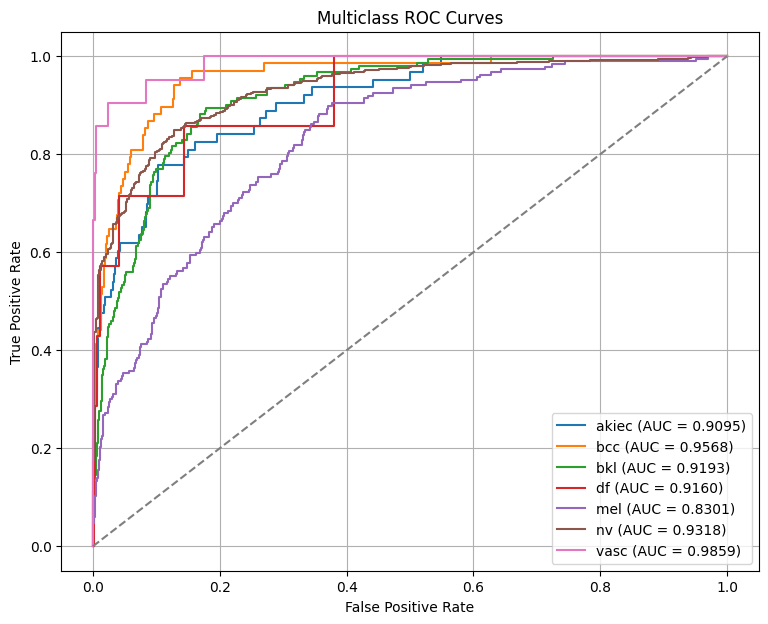

In [33]:
# ============================================================
# BLOCK 31 : ROC CURVES
# ============================================================

plt.figure(figsize=(9, 7))

for i, cls in enumerate(classes):
    fpr, tpr, _ = roc_curve(
        y_true_onehot[:, i],
        y_prob[:, i]
    )

    roc_value = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{cls} (AUC = {roc_value:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass ROC Curves")
plt.legend()
plt.grid()
plt.show()

In [34]:
# ============================================================
# BLOCK 32 : MEDICAL PERFORMANCE METRICS
# ============================================================

balanced_acc = balanced_accuracy_score(y_true, y_pred)
mcc = matthews_corrcoef(y_true, y_pred)
kappa = cohen_kappa_score(y_true, y_pred)

print("=" * 60)
print("Medical Performance Metrics")
print("=" * 60)
print(f"Balanced Accuracy : {balanced_acc:.4f}")
print(f"MCC               : {mcc:.4f}")
print(f"Cohen's Kappa     : {kappa:.4f}")
print("=" * 60)

Medical Performance Metrics
Balanced Accuracy : 0.6170
MCC               : 0.5296
Cohen's Kappa     : 0.5108


In [35]:
# ============================================================
# BLOCK 33 : PER-CLASS SENSITIVITY & SPECIFICITY
# ============================================================

medical_results = []

for i, cls in enumerate(classes):
    TP = cm[i, i]
    FN = np.sum(cm[i, :]) - TP
    FP = np.sum(cm[:, i]) - TP
    TN = np.sum(cm) - (TP + FN + FP)

    sensitivity = TP / (TP + FN) if (TP + FN) else 0
    specificity = TN / (TN + FP) if (TN + FP) else 0

    medical_results.append({
        "Class": cls,
        "Sensitivity": sensitivity,
        "Specificity": specificity
    })

medical_df = pd.DataFrame(medical_results)

print(medical_df)

   Class  Sensitivity  Specificity
0  akiec     0.412698     0.992313
1    bcc     0.544118     0.983871
2    bkl     0.855263     0.837556
3     df     0.428571     0.990585
4    mel     0.465241     0.901301
5     nv     0.756024     0.923695
6   vasc     0.857143     0.995248


In [36]:
# ============================================================
# BLOCK 34 : SAVE FINAL RESULTS
# ============================================================

results = {
    "Test Accuracy": test_accuracy,
    "Test Loss": test_loss,
    "Weighted Precision": precision,
    "Weighted Recall": recall,
    "Weighted F1": f1,
    "Balanced Accuracy": balanced_acc,
    "MCC": mcc,
    "Cohen Kappa": kappa,
    "Weighted ROC-AUC": roc_auc
}

results_df = pd.DataFrame([results])

results_path = os.path.join(
    SAVE_DIR,
    "final_results.csv"
)

results_df.to_csv(results_path, index=False)

medical_path = os.path.join(
    SAVE_DIR,
    "medical_performance_metrics.csv"
)

medical_df.to_csv(medical_path, index=False)

print("Final results saved successfully ✅")
print("Overall:", results_path)
print("Medical:", medical_path)

Final results saved successfully ✅
Overall: /content/drive/MyDrive/HAM10000_Model/final_results.csv
Medical: /content/drive/MyDrive/HAM10000_Model/medical_performance_metrics.csv
